# 33장 · 같은 검색 함수를 Tool로 포장하기

모델이 ‘도서관 자료를 찾아 달라’고 요청해도 검색은 아직 실행되지 않았습니다. 도구 요청의 이름과 인자를 읽고, 검색을 실행한 뒤 요청 ID가 붙은 결과를 돌려보냅니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 langchain-core 1.6.12, pydantic 2.14.1입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 도구 명세와 호출 요청 읽기

같은 retrieve를 수업용 검색 도구로 감쌉니다. 이름과 인자 규칙은 모델이 검색 요청을 작성할 때 읽습니다. 이 노트북에서는 모델이 보낼 법한 요청 한 건을 직접 만들어 네트워크 없이 실제 LangChain 도구에 전달합니다.


### 셀 01 · 제공 셀 · 검색 도구 등록하기

자료와 검색 함수는 30장과 같습니다. 맨 아래 search_documents의 이름과 k 인자 규칙만 찾아보세요.

In [1]:
records = [{'id': 'library-1',
  'text': '도서 대출 기간은 14일입니다.',
  'source': '가상 도서관 이용 안내',
  'page': 1},
 {'id': 'library-2',
  'text': '도서관은 월요일에 휴관합니다.',
  'source': '가상 도서관 이용 안내',
  'page': 2},
 {'id': 'library-3',
  'text': '무인 반납함은 24시간 이용할 수 있습니다.',
  'source': '가상 도서관 이용 안내',
  'page': 3}]
terms = ("대출", "휴관", "반납")

def retrieve(question, k=1):
    query = [int(term in question) for term in terms]
    if not any(query):
        return []
    def distance(row):
        vector = [int(term in row["text"]) for term in terms]
        return sum((a-b)**2 for a, b in zip(query, vector)), row["id"]
    return sorted(records, key=distance)[:k]

from langchain_core.tools import tool
from langchain_core.messages import AIMessage
from pydantic import BaseModel, ConfigDict, StrictInt, StrictStr, Field

class SearchArgs(BaseModel):
    model_config = ConfigDict(extra="forbid")
    question: StrictStr
    k: StrictInt = Field(default=2, ge=1)

@tool("search_documents", args_schema=SearchArgs, response_format="content_and_artifact")
def search_documents(question: str, k: int = 2):
    """가상 도서관의 대출·휴관·반납 안내를 찾습니다."""
    if not question.strip():
        raise ValueError("질문을 입력하세요.")
    found = retrieve(question, k)
    return "\n".join(row["text"] for row in found), found

print(search_documents.name)

search_documents


등록된 이름은 search_documents입니다. 이 이름을 찍은 것만으로는 검색을 한 번도 실행하지 않았습니다.

### 셀 02 · 요청 한 건 만들기

질문과 k가 담긴 도구 호출을 AIMessage에서 꺼내세요.

In [2]:
request = AIMessage(content='', tool_calls=[{'id': 'search-1', 'name': 'search_documents', 'args': {'question': '대출 기간은?', 'k': 1}, 'type': 'tool_call'}])
call = request.tool_calls[0]
print(call['args'])

{'question': '대출 기간은?', 'k': 1}


대출 질문과 검색 상한 1이 나옵니다. 이 시점에는 문서가 없습니다.

## 요청 ID를 붙여 검색 결과 돌려주기

invoke에 인자만 넘길 때와 달리 호출 ID까지 포함한 요청을 건네면 ToolMessage에서 어느 요청의 결과인지 읽을 수 있습니다. 화면에는 실제 검색 자료를 싣고 메시지에는 다음 판단에 필요한 내용을 담습니다.

<!-- motion:reply-envelope -->
**search-1과 library-1은 각각 무엇을 가리킬까요?**

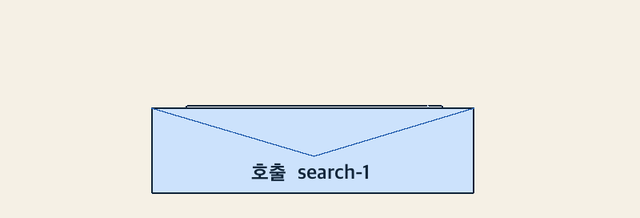

답장 봉투의 search-1은 도구 호출 ID입니다. 봉투 안에서 꺼낸 library-1은 검색한 문서 ID입니다.
<!-- /motion -->


### 과제 03 · 답을 기다리는 요청과 결과 연결하기

call을 도구로 실행한 뒤 tool_call_id와 첫 문서의 id를 표시하세요.

이 셀의 content에는 검색한 문서의 본문이 일반 문자열로 들어갑니다. artifact에는 id·text·source·page를 보관합니다. 참고 구현은 content를 JSON 문자열로 만들지만 여기서는 도서관 안내 문장을 그대로 읽으세요.

In [3]:
# call 전체를 search_documents.invoke에 넘기세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>reply = search_documents.invoke(call)
print(reply.tool_call_id, reply.artifact[0][&#x27;id&#x27;])</code></pre>
<p>실행 결과</p><pre><code>search-1 library-1</code></pre>
<p>search-1은 요청 식별자, library-1은 근거 문서 식별자입니다. 이 둘을 바꿔 쓰면 다음 판단에서 어떤 요청에 답이 왔는지 찾기 어렵습니다.</p>
</details>

## 돌아보기

도구 응답이 빈 목록이면 호출 자체는 끝난 상태입니다. 검색 호출을 건너뛴 경우와 구별할 수 있도록 요청 ID, 실행 여부, 자료 목록을 함께 읽으세요.

### 검색 요청과 결과의 한 차례 왕복

**사용자가 질문한다**　질문 문자열을 메시지로 보관합니다.

```
대출 기간은?
```

**검색을 요청한다**　아직 검색은 실행되지 않았습니다.

```
name=search_documents
id=search-1
args={question: 대출 기간은?, k: 1}
```

**같은 retrieve를 부른다**　실행 후 검증한 근거를 ToolMessage로 돌려줍니다.

```
tool_call_id=search-1
status=success
artifact=[library-1]
```

**결과를 읽고 검색 선택을 마친다**　이 fixture는 추가 도구를 요청하지 않습니다. A1 답변 생성은 별도 단계입니다.

```
tool_calls=[]
```
